# <span style="color:green"> Numerical Simulation Laboratory (NSL) </span>
## <span style="color:blue">  Numerical exercises 10</span>

### Exercise 10.1

Choose **ONLY ONE** of the two following possibilities:

1. Parallelize with MPI libraries your Genetic Algorithm code in order to solve the TSP by performing a *Genetic Search* with (up to) 11 **parallel GA searches of the optimal path**:
each node should perform an independent GA search, the so-called *Continent*, **but** every $N_{migr}$ generations the *Continents* should exchange their best individuals randomly.

2. Starting from your Genetic Algorithm code implement a **Parallel Tempering algorithm** (Simulated Annealing with many temperatures). Parallelize with MPI libraries your algorithm in order to solve the TSP where each computing node, up to 11, is characterized by a different temperature or a limited set of temperatures (if you need more than 11 temperatures). Use your genetic operators (except crossover) as trial moves for the Metropolis algorithm and **add a trial move that proposes an exchange of paths among adjacent temperatures (nodes)** (see lecture 8 for the acceptance formula). The candidate solution of the TSP will appear on the node with the lowest temperature.

### Exercise 10.2

Apply your parallel code to the TSP problem for 110 italian "capoluoghi di provincia" longitude and latitude coordinates in the *cap_prov_ita.dat* file.

If your choice in Exercise 10.1 is option 1, do you improve with respect using the same number of computing cores but with **independent GA searches** ?

If your choice in Exercise 10.1 is option 2, by using a number of temperatures equal to the number of individuals in your **non-parallel Genetic Algorithm code**, do you "improve" with respect to it?

# <span style="color:green"> RESULTS: </span>

## Parallel Tempering algorithm

We chose to implement the Parallel Tempering (PT) algorithm, parallelized with MPI, to solve the TSP.

The PT algorithm runs several replicas of the same system at the same time, each one performing a Metropolis simulation at its own fixed temperature $T_k$. The "energy" on which Metropolis acts is the length $L^{(1)}$ of the path (with $k_B=1$, so $T$ has the dimensions of a length), and the weight of a path is $e^{-L^{(1)}/T}$. Having several temperatures allows a better exploration of the configuration space: hot replicas cross the barriers between local minima easily but fluctuate far from the optimum, while cold ones refine a path but could get trapped in a local minimum. PT combines the two by proposing, every <small><code>swap_freq</code></small> steps, the exchange of the paths of two adjacent temperatures $T_i<T_j$, accepted with a probability of
$$
A=\min\Big\{1,\ \exp\big[(\beta_i-\beta_j)\,(L_i-L_j)\big]\Big\},\qquad \beta=\frac1T ,
$$
where $L_i$ and $L_j$ are the lengths $L^{(1)}$ of the two paths. This is the Metropolis acceptance for the ratio of the joint weights after and before the exchange, so the swap satisfies the detailed balance and every replica keeps sampling its own Boltzmann distribution. If the colder replica holds the longer path $L_i>L_j$, the exponent is positive and the exchange is always accepted. In this way each path performs a sort of random walk in the temperature space: the good paths found at high temperature are passed down to the coldest replica, where the best path is read.

We used $11$ temperatures, one for each process, from $T_{\min}=0.06$ to $T_{\max}=0.3$ with geometric spacing, $T_{k+1}/T_k=5^{1/10}\simeq1.17$. The spacing must be small enough for the distributions of $L^{(1)}$ of neighbouring replicas to overlap, otherwise the exchanges are never accepted; with $11$ replicas this range satisfies the condition.

To implement the algorithm each replica is an object of the class <small><code>PT</code></small>, which uses the class <small><code>trip</code></small> of Exercise 9 to store the path and to generate the trial moves of the Metropolis algorithm:
<small>

```cpp
class PT {
    trip   _current_trip, _best_trip;    // current path of the replica and best path found by it
    double _current_loss, _best_loss;    // corresponding L^(1)
    double _temp;                        // temperature of this replica (fixed)
    Random _rnd;                         // independent random sequence for each process
    int    _rank, _size;                 // MPI rank and number of processes
    int    _proposed_swaps, _accepted_swaps;
  public:
    bool SA_step();                          // one Metropolis step at temperature _temp
    bool PT_swap(int step, int swap_freq);   // attempt to exchange the path with a neighbour
};
```
</small>

#### Metropolis step:
The trial moves are the mutations used in the genetic algorithm, without crossover, since every replica holds a single path that mutates over time. At every step exactly one of the mutations is chosen, with a specific probability: swap $20\%$, shift $15\%$, block permutation $10\%$, inversion $55\%$. The blocks of swap, shift and permutation are short, while the length of the inversion is drawn from an exponential law with mean $N/8$, so that long inversions, which are needed to remove long crossings, are rare but possible. The move is accepted with the Metropolis rule (with $k_B=1$):
<small>

```cpp
trip proposal = _current_trip;
const double prob = _rnd.Rannyu();
if      (prob < 0.20) proposal.random_swap_mutation(_rnd);
else if (prob < 0.35) proposal.shift_mutation(_rnd, block, shift);
else if (prob < 0.45) proposal.block_permutation_mutation(_rnd, block);
else {
    int block = 2 + int(-std::log(1.0 - _rnd.Rannyu()) * n_cities / 8.0);   // exponential length
    proposal.inversion_mutation(_rnd, std::min(block, n_cities - 2));
}

double proposal_loss = proposal.distance_L1();
double delta = proposal_loss - _current_loss;
bool acceptance = (delta <= 0.0) || (_rnd.Rannyu() < std::exp(-delta / _temp));
if (acceptance) { _current_trip = proposal; _current_loss = proposal_loss; }   // and update the best path
```
</small>

#### Path swap:
Only adjacent temperatures can exchange paths and the acceptance probability $A$ falls rapidly when the temperatures are far apart, because the distributions of $L^{(1)}$ of the two replicas hardly overlap and the exchange would almost always be rejected (the exponent $(\beta_i-\beta_j)(L_i-L_j)$ is large and negative). A path can still travel between distant temperatures through a sequence of exchanges between neighbours. To let the paths move both towards higher and towards lower temperatures, the pairs alternate at every attempt with an even/odd scheme: $(0,1),(2,3),\dots$ and then $(1,2),(3,4),\dots$, so that every process has at most one partner and a replica exchanges alternately with its upper and with its lower neighbour. The partners first exchange $(L,T)$, then the lower rank computes $A$ and sends the outcome back. If the swap is accepted the two processes exchange the paths, while the temperatures stay with the ranks:
<small>

```cpp
const int parity  = (step / swap_freq) % 2;                          // choose the partner according to the parity of the attempt
const int partner = ((_rank % 2) == parity) ? _rank + 1 : _rank - 1;
if (partner < 0 || partner >= _size) return false;                  // edge ranks sit out

MPI_Sendrecv(rank, 2, MPI_DOUBLE, partner, 0, other, 2, MPI_DOUBLE, partner, 0, MPI_COMM_WORLD, MPI_STATUS_IGNORE);   // (L, T)

if (is_master) {                                                    // the lower rank decides
    const double delta = (1./_temp - 1./other[1]) * (_current_loss - other[0]);
    swapped = (delta >= 0.0 || _rnd.Rannyu() < std::exp(delta));
    MPI_Send(&swapped, 1, MPI_CXX_BOOL, partner, 1, MPI_COMM_WORLD);
} else MPI_Recv(&swapped, 1, MPI_CXX_BOOL, partner, 1, MPI_COMM_WORLD, MPI_STATUS_IGNORE);

if (swapped) MPI_Sendrecv(send_buffer.data(), 3*n_cities, MPI_DOUBLE, partner, 2,
                          recv_buffer.data(), 3*n_cities, MPI_DOUBLE, partner, 2, MPI_COMM_WORLD, MPI_STATUS_IGNORE);
```
</small>

#### Parallel compilation and execution:
The code is parallelized with MPI (Message Passing Interface): the same executable is launched on $11$ processes, called ranks and numbered from $0$ to $10$, each with its own memory. Each process is one replica of the system, it holds its own path, its own temperature (rank $0$ is the coldest, rank $10$ the hottest) and its own random number generator, seeded differently for each rank so that the replicas are independent. The processes perform their Metropolis steps without any communication; messages are exchanged only in <small><code>PT_swap</code></small>, every <small><code>swap_freq</code></small> steps and only between neighbouring ranks. These messages consist of $2$ numbers for the proposal and $3N$ numbers for the paths. They are relatively short, so the cost of the communication is negligible compared with that of the Metropolis steps. On a machine with at least $11$ cores, the $11$ replicas therefore run in about the same wall time as a single one, which is one of the advantages of a parallelized code.

The program is compiled with <small><code>mpicxx</code></small>, a wrapper around the C++ compiler that adds the MPI headers and libraries, and it is run with <small><code>mpirun</code></small>, where <small><code>-np</code></small> sets the number of processes. Our machine has only $4$ physical cores, so the $11$ processes had to be launched with the option <small><code>--oversubscribe</code></small>, this means that they share the cores, and the wall time is therefore longer than with one core for each replica.

<small>

```bash
mpicxx -O3 -std=c++17 -o PT main.cpp ../../LIBS/GA/PT.cpp ../../LIBS/GA/trip.cpp ../../LIBS/PRNG/random.cpp
mpirun --oversubscribe -np 11 ./PT        # 4 physical cores: the 11 processes share them
```
</small>

## Exercise 10.1
We tested our PT algorithm on the two sets of $34$ cities of notebook 9 (on a circumference and inside a square), running $10^6$ steps for each of the $11$ replicas and comparing the results obtained in the two cases.

For each set the figure has three panels.

The first panel shows the convergence of $L^{(1)}$. We plotted the current $L^{(1)}$ of every replica as a function of the step, with logarithmic axes and coloured by temperature (blue = cold, red = hot). The black curve is the best $L^{(1)}$ found so far (rank $0$); it decreases by steps, each one corresponding to a better path that has been passed down to the coldest replica through the swaps.

The second panel shows the distribution of $L^{(1)}$ for each temperature. For each replica, we plotted the distribution of the values of $L^{(1)}$ visited after discarding the first $20\%$ of the steps (as equilibration time), as a violin plot whose black mark is the median, and we added a dashed line to represent the best path found. The overlap between the distributions of neighbouring temperatures is what allows the swaps to be accepted.

The last panel shows the best path found by the algorithm, with the first city marked by a star.

In [2]:
import glob, re
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.cm import ScalarMappable
from matplotlib.ticker import FuncFormatter

In [3]:
INP = "INPUT"
OUT = "OUTPUT"

def load_table(fname):
    """Read a numeric table, skipping header/comment lines."""
    rows = []
    with open(fname) as f:
        for line in f:
            parts = line.split()
            if not parts:
                continue
            try:
                rows.append([float(x) for x in parts])
            except ValueError:
                continue
    return np.array(rows)

def load_losses(folder, name):
    """Load loss_<name>_rank_k.dat for all ranks, sorted numerically.
    np.loadtxt is much faster than the line-by-line reader (the Italy files have ~1e6 rows)."""
    files = sorted(glob.glob(f"{OUT}/{folder}/loss_{name}_rank_*.dat"),
                   key=lambda s: int(re.search(r"rank_(\d+)", s).group(1)))
    return [np.loadtxt(f, comments="#") for f in files]

def log_binned(y, n_bins=150):
    """Average y in logarithmically spaced bins of the row index -> (index of bin centre, bin mean)."""
    n = len(y)
    edges = np.unique(np.concatenate([[0], np.geomspace(1, n, n_bins).astype(int), [n]]))
    mean = np.add.reduceat(y, edges[:-1]) / np.diff(edges)
    centre = (edges[:-1] + edges[1:] - 1) // 2
    return centre, mean

def split_loss(tab):
    """Columns of loss_*_rank_k.dat: step, T, current_loss, best_loss."""
    return tab[:, 0], tab[:, 1], tab[:, 2], tab[:, 3]

def path_xy(cities, fname):
    """Closed path coordinates from best_path file (city indices, 0/1-based, or coordinates)."""
    tab = load_table(fname)
    if tab.shape[0] == 1 or tab.shape[1] == 1:   # one index per line (or all on one line)
        p = tab.ravel().astype(int)
        if p.min() == 1:
            p = p - 1
        assert len(set(p)) == len(cities), "The path does not visit every city exactly once!"
        xy = cities[p]
    else:                                         # file already contains x, y
        xy = tab[:, -2:]
    return np.vstack([xy, xy[0]])

In [ ]:
def plot_pt(title, cities_file, folder, name, xlabel="x", ylabel="y", burn_in=0.2):
    cities = load_table(cities_file)[:, -2:]
    xy = path_xy(cities, f"{OUT}/{folder}/best_path_{name}.dat")
    L1 = np.sum(np.linalg.norm(np.diff(xy, axis=0), axis=1))

    losses = [split_loss(t) for t in load_losses(folder, name)]   # (step, T, current, best) per rank
    Ts = np.array([l[1][0] for l in losses])
    norm, cmap = LogNorm(Ts.min(), Ts.max()), plt.cm.coolwarm     # temperatures are geometrically spaced

    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(20, 6), gridspec_kw={"width_ratios": [1.3, 1, 1]})

    # convergence 
    for step, T, cur, best in losses:
        c, m = log_binned(cur)
        ax1.plot(step[c], m, color=cmap(norm(T[0])), lw=1.4)
    step0, _, cur0, best0 = losses[0]
    c, _ = log_binned(cur0)
    ax1.plot(step0[c], best0[c], "k-", lw=2.5, label=r"best $L^{(1)}$ (rank 0)")
    ax1.set_xscale("log"); ax1.set_yscale("log")
    fmt = FuncFormatter(lambda v, _: f"{v:g}")
    ax1.yaxis.set_major_formatter(fmt); ax1.yaxis.set_minor_formatter(fmt)
    ax1.set_xlabel("Step"); ax1.set_ylabel(r"$L^{(1)}$")
    ax1.set_title(f"Convergence - {title}")
    ax1.grid(alpha=0.3, which="both")
    ax1.legend(loc="upper right")
    fig.colorbar(ScalarMappable(norm, cmap), ax=ax1, label="Temperature T")

    # distribution of the current loss at each temperature (after burn-in) 
    data = [cur[int(burn_in * len(cur))::max(1, len(cur) // 20000)] for _, _, cur, _ in losses]
    parts = ax2.violinplot(data, positions=range(len(Ts)), widths=0.9, showextrema=False, showmedians=True)
    for k, body in enumerate(parts["bodies"]):
        body.set_facecolor(cmap(norm(Ts[k]))); body.set_alpha(0.85)
    parts["cmedians"].set_color("k")
    ax2.axhline(L1, color="k", ls="--", lw=1.2, label="best path found")
    ax2.set_xticks(range(len(Ts)))
    ax2.set_xticklabels([f"{T:.3g}" for T in Ts], rotation=45)
    ax2.set_xlabel("Temperature T (rank 0 → 10)")
    ax2.set_ylabel(r"$L^{(1)}$ (current)")
    ax2.set_title("Distribution of L per temperature")
    ax2.grid(alpha=0.3)
    ax2.legend(loc="upper left")

    # best path
    ax3.plot(xy[:, 0], xy[:, 1], "-o", color ='#0c459a', ms=4, lw=1.2)
    ax3.plot(*xy[0], "r*", ms=15, label="start")
    ax3.set_aspect("equal")
    ax3.set_xlabel(xlabel); ax3.set_ylabel(ylabel)
    ax3.set_title(f"Best path - {title} (L = {L1:.4f})")
    ax3.legend(loc="upper right")

    fig.tight_layout()
    plt.show()

    print(f"{title}: L1 from best_path = {L1:.4f} | min best_loss over ranks = "
          f"{min(l[3].min() for l in losses):.4f}")

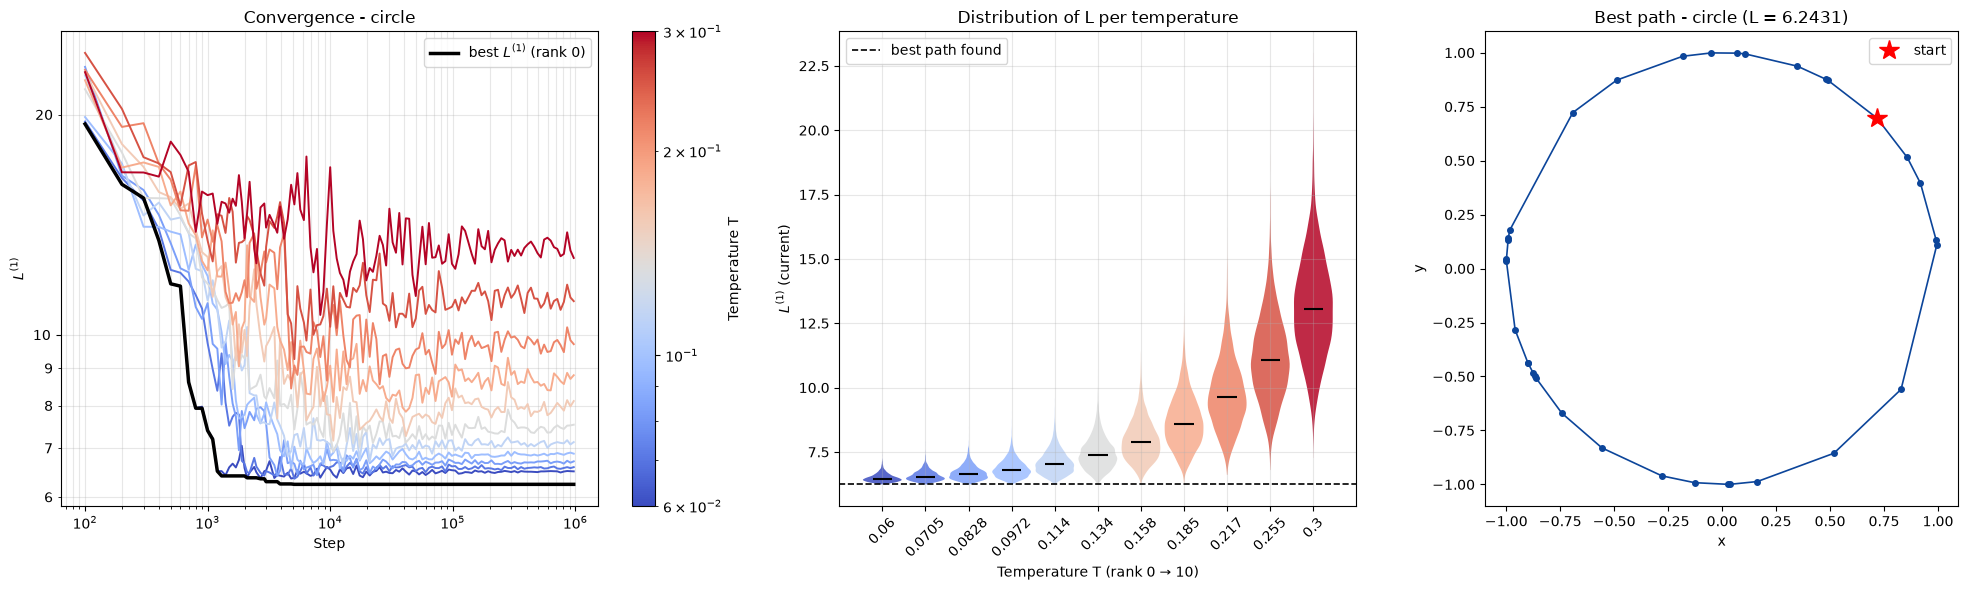

circle: L1 from best_path = 6.2431 | min best_loss over ranks = 6.2431


In [5]:
plot_pt("circle", f"{INP}/circle.dat", "CIRCLE", "circle")

As we said in notebook 9, for the cities on a circumference the best path is the convex polygon, so the exact minimum is $L^{(1)}=6.2431$, this value was already found by the GA, and the PT finds it as well. In the convergence plot all the replicas start from random paths, much longer than the optimum, and drop quickly, because every move that shortens the path is accepted. Then they separate according to their temperature, the best $L^{(1)}$ indicated by the black line reaches the minimum well before the end of the run and then stays on it. The cold replicas settle slightly above the best path that is because at $T>0$ a move that lengthens the path by $\Delta L$ is still accepted with probability $e^{-\Delta L/T}$, so the replica keeps fluctuating around the minimum instead of staying on it. The hot ones instead fluctuate around much longer paths, because uphill moves with $\Delta L\lesssim T$ are accepted often enough to prevent them from freezing.

The distribution plot shows the same. At each temperature a replica samples the paths with probability proportional to $g(L)\,e^{-L/T}$, where $g(L)$ is the number of paths of length $L$. The two factors compete: while $e^{-L/T}$ favours the short paths, $g(L)$ favours the long ones, since there are many more long paths than short ones. At low temperature the first factor dominates, so the distribution is narrow and close to the best path found indicated by the dashed line. As $T$ increases the long paths weigh more, so the distribution moves to larger values of $L^{(1)}$ and becomes wider. Accordingly, the median of $L^{(1)}$ grows monotonically with $T$.

The overlap of the distributions is what makes the swaps happening. A swap between two neighbouring temperatures $T_i<T_j$ is always accepted if the colder replica holds the longer path ($L_i>L_j$), otherwise it is accepted with probability $e^{-(\beta_i-\beta_j)(L_j-L_i)}$. If the distributions were well separated we would always have $L_j\gg L_i$, and almost no swap would be accepted and the replicas would be independent Metropolis runs, with no transfer of good paths from the hot to the cold replicas. Since the distributions of neighbouring temperatures overlap, as the plot shows, a fraction of the proposed swaps is accepted and the paths can diffuse through the whole range of temperatures.

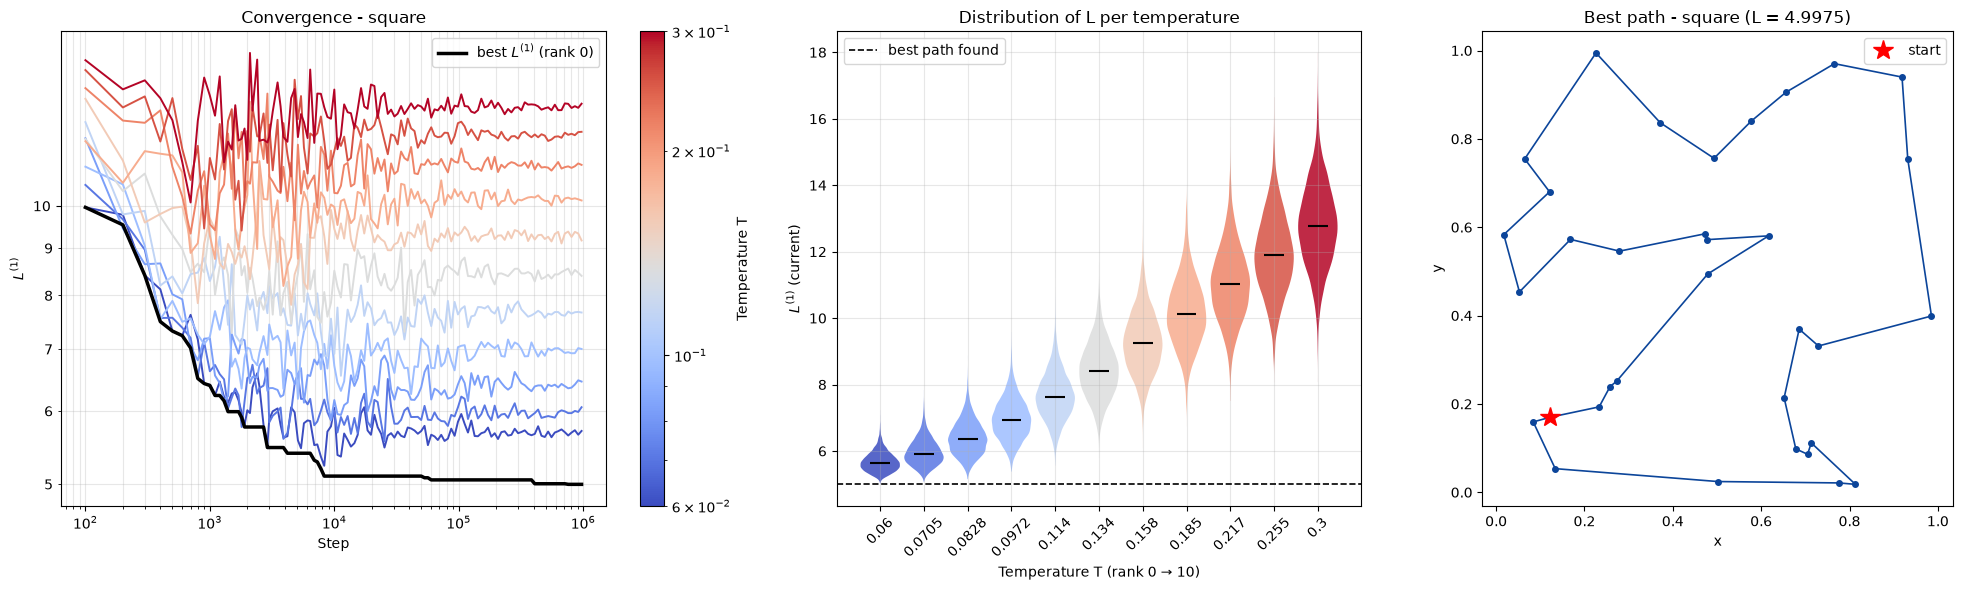

square: L1 from best_path = 4.9975 | min best_loss over ranks = 4.9975


In [6]:
plot_pt("square", f"{INP}/square.dat", "SQUARE", "square")

For the cities inside a unit square the best path found was $L^{(1)}=4.9975$. For the same cities the GA algorithm found $L^{(1)}=5.1208$, so PT gives a path that is $2.4\%$ shorter. As for the GA, the best $L^{(1)}$ decreases by steps and it settles on its final value after about $10^5$ steps, later than for the circle as we could expect. The landscape is more rugged: the median of the coldest replica lies well above the best path, because even at $T=0.06$ the Boltzmann weight $g(L)\,e^{-L/T}$ is dominated by the many paths slightly longer than the minimum rather than by the few shortest ones. The best path could therefore be a rare low $L^{(1)}$ fluctuation, and the coldest replica does not stay on it.

## Exercise 10.2

We will now apply the Parallel Tempering algorithm to the TSP on the $110$ Italian "capoluoghi di provincia", whose longitude and latitude are taken from the file <small><code>cap_prov_ita.dat</code></small>. We also ran the GA of Exercise 9 on the same cities, in order to compare the two methods. We used one process for each of the $11$ temperatures, as in the previous tests, and the first figure, which shows the results of the PT algorithm, has the same three panels as before.

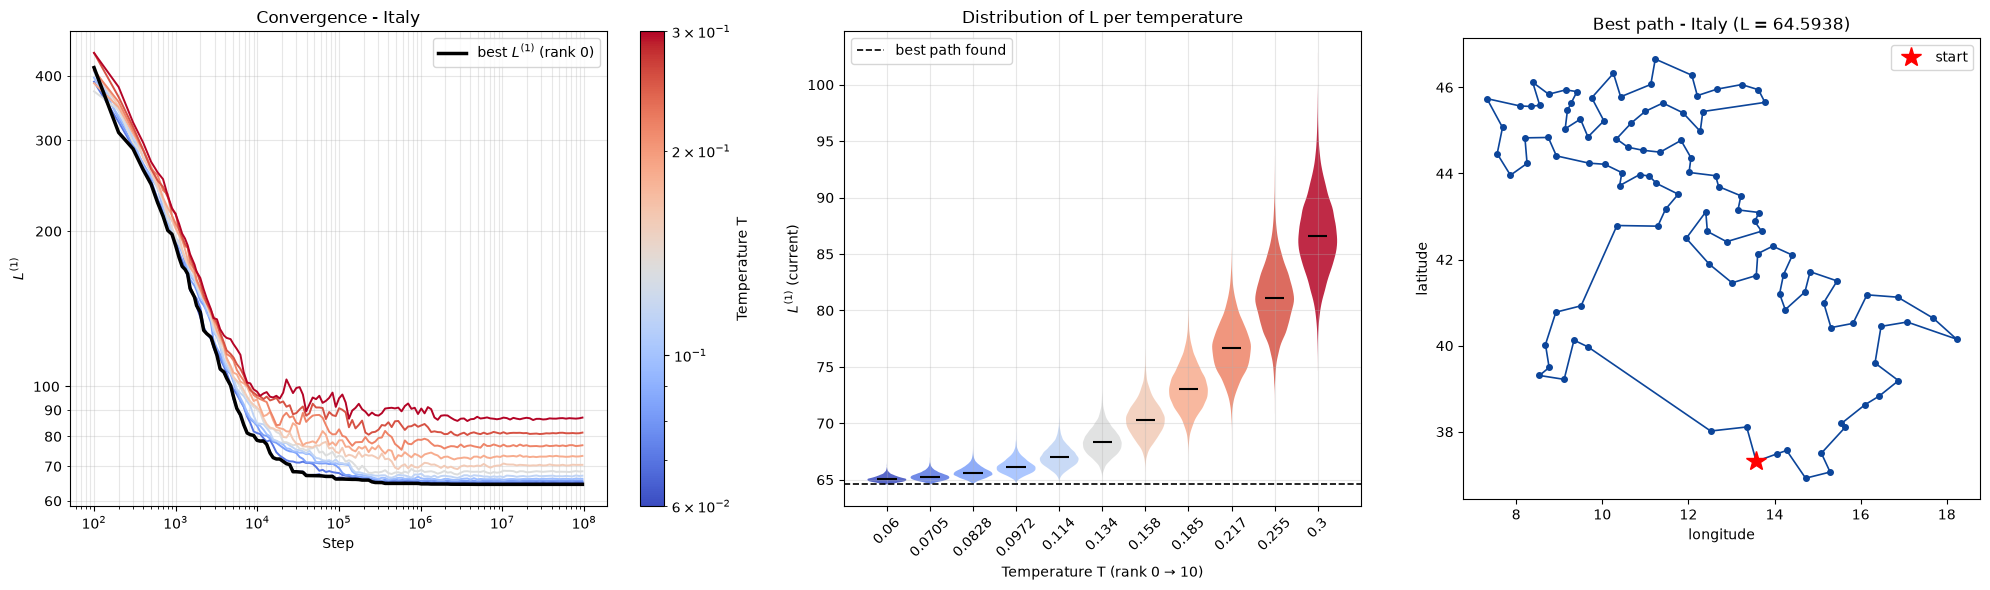

Italy: L1 from best_path = 64.5938 | min best_loss over ranks = 64.5938


In [7]:
plot_pt("Italy",  f"{INP}/cap_prov_ita.dat", "ITALY", "italy", "longitude", "latitude")

The best path found is $L^{(1)}=64.5938$. The behaviour is the same as for the previuous tests: the best $L^{(1)}$ drops from about $400$ to about $66$ within the first $10^5$ steps and then improves only slowly down to its final value. The hot replicas keep fluctuating without freezing and the distributions of neighbouring temperatures overlap, so the swaps are accepte with an acceptance rate of $0.3634$.

For the last question, the exercise asked whether PT improves on the non-parallel GA of Exercise 9 (with $M=300$ individuals), using a number of temperatures equal to the number of individuals. The two algorithms have a different computational cost per iteration: a GA generation requires $300$ evaluations of $L^{(1)}$, one for each individual of the population; while a PT step requires $11$, one for each replica. Comparing them as a function of the number of generations and of steps would therefore be unfair, so we compared them at equal computational effort, which means as a function of the total number of evaluations of $L^{(1)}$, which does not depend on the machine nor on the implementation. For simplicity we used $11$ temperatures, one for each process, and not $300$. The GA ran for $2\cdot10^4$ generations, which is $6\cdot10^6$ evaluations, while PT ran for $10^8$ steps, hence $1.1\cdot10^9$ evaluations: because the PT has more evaluation, besides the final results, we also report the best path found by PT after the same number of evaluations as the GA. The following figure shows the best $L^{(1)}$ as a function of the number of evaluations, together with the best path found by each algorithm.

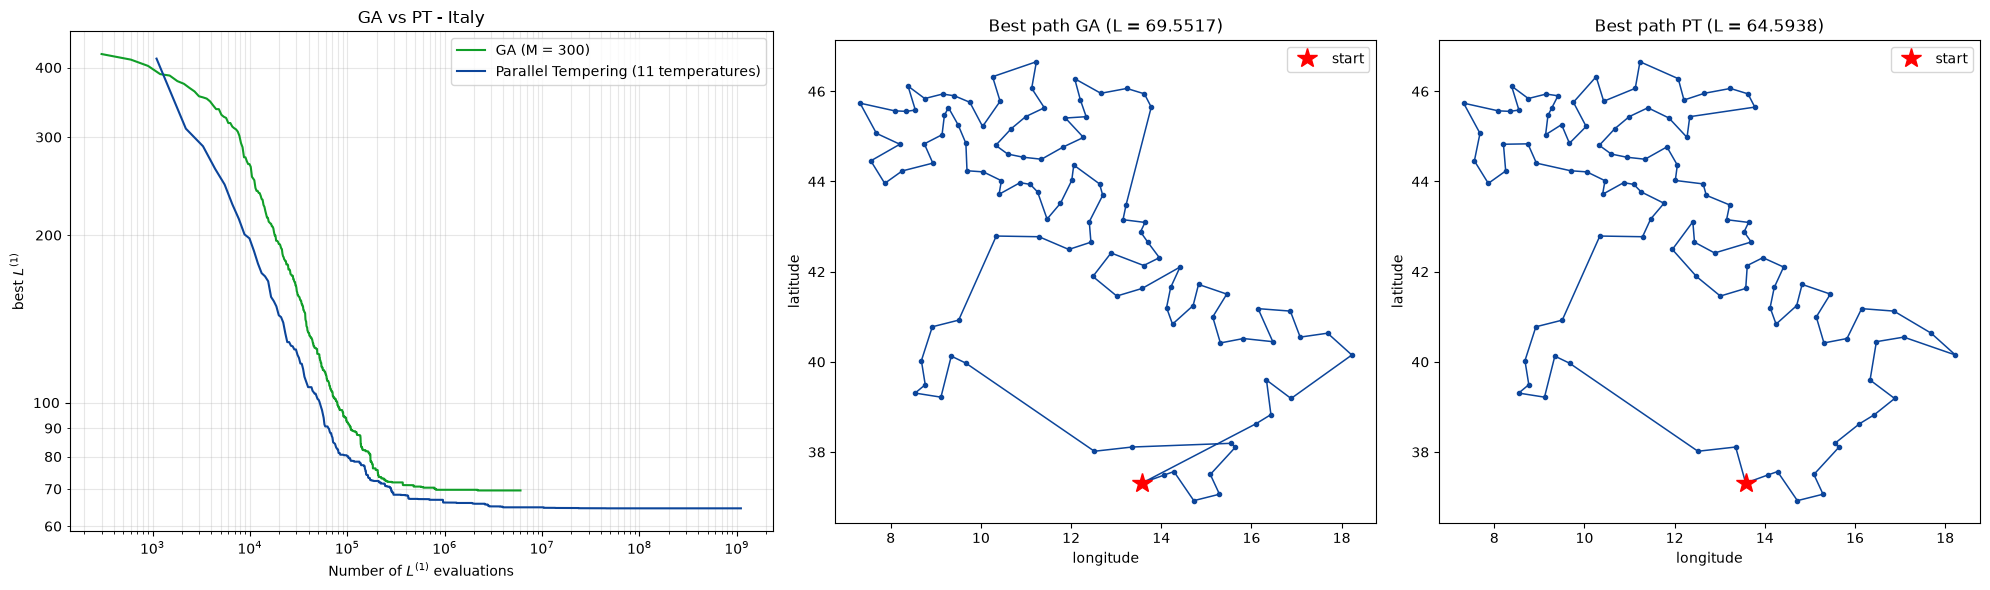

       final L1   evaluations
  GA    69.5517         6e+06
  PT    64.5938       1.1e+09
PT at the same budget as the GA (6e+06 evaluations): L1 = 64.8656


In [ ]:
GA_DIR = "../Lezione_9/OUTPUT"
M_GA   = 300        # individuals in the GA
N_TEMPS = 11        # temperatures used in the PT run (set to M_GA if you rerun the PT with 300 temperatures)

cities = load_table(f"{INP}/cap_prov_ita.dat")[:, -2:]

#GA: best L1 per generation (skip generation 0 because of the log axis)
ga = load_table(f"{GA_DIR}/best_loss_italy.dat")          
ga_best  = ga[1:, 1]
ga_evals = M_GA * ga[1:, 0]                               # ~M evaluations of L1 per generation

#PT: best L1 of rank 0 
step, _, _, pt_best = split_loss(load_losses("ITALY", "italy")[0])
pt_evals = N_TEMPS * step                                 # 1 proposed move per temperature per step

#GA best path: 
with open(f"{GA_DIR}/best_trip_italy.dat") as f:
    for line in f:
        last = line
p = np.array([int(x) for x in last.split()[2:]])          
if p.min() == 1:
    p = p - 1
assert len(set(p)) == len(cities), "The GA path does not visit every city exactly once!"
xy_ga = cities[p]
xy_pt = path_xy(cities, f"{OUT}/ITALY/best_path_italy.dat")
L_ga = np.sum(np.linalg.norm(np.diff(xy_ga, axis=0), axis=1))
L_pt = np.sum(np.linalg.norm(np.diff(xy_pt, axis=0), axis=1))

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(20, 6), gridspec_kw={"width_ratios": [1.3, 1, 1]})

ax1.plot(ga_evals, ga_best, color = '#109e28', label=f"GA (M = {M_GA})")
ax1.plot(pt_evals, pt_best, color = '#0c459a', label=f"Parallel Tempering ({N_TEMPS} temperatures)")
ax1.set_xscale("log"); ax1.set_yscale("log")
fmt = FuncFormatter(lambda v, _: f"{v:g}")
ax1.yaxis.set_major_formatter(fmt); ax1.yaxis.set_minor_formatter(fmt)
ax1.set_xlabel(r"Number of $L^{(1)}$ evaluations")
ax1.set_ylabel(r"best $L^{(1)}$")
ax1.set_title("GA vs PT - Italy")
ax1.grid(alpha=0.3, which="both")
ax1.legend()

for ax, xy, name, L in [(ax2, xy_ga, "GA", L_ga), (ax3, xy_pt, "PT", L_pt)]:
    ax.plot(xy[:, 0], xy[:, 1], "-o", ms=3, lw=1.1, color = '#0c459a')
    ax.plot(*xy[0], "r*", ms=15, label="start")
    ax.set_aspect("equal")
    ax.set_xlabel("longitude"); ax.set_ylabel("latitude")
    ax.set_title(f"Best path {name} (L = {L:.4f})")
    ax.legend(loc="upper right")

fig.tight_layout()
plt.show()

# summary table
print(f"{'':>4} {'final L1':>10} {'evaluations':>13}")
print(f"{'GA':>4} {ga_best.min():10.4f} {ga_evals[-1]:13.3g}")
print(f"{'PT':>4} {pt_best.min():10.4f} {pt_evals[-1]:13.3g}")
k = min(np.searchsorted(pt_evals, ga_evals[-1]), len(pt_evals) - 1)
print(f"PT at the same budget as the GA ({ga_evals[-1]:.3g} evaluations): L1 = {pt_best[k]:.4f}")

The results of the simulations are reported in the table above. From the gathered data we can safely say that PT performs better than the GA as at the same number of evaluations the path is $6.7\%$ shorter ($64.8656$ against $69.5517$), and the final one reached by PT is $7.1\%$ shorter. In the convergence plot the PT curve lies below the GA one after the first few $10^3$ evaluations, and the GA flattens at $L^{(1)}\approx70$. Most of the gain is obtained early and with about $180$ times more evaluations ($6\cdot10^6\to1.1\cdot10^9$) PT improves by only $0.4\%$.